In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting style
sns.set_theme(style="whitegrid")
import warnings

warnings.filterwarnings("ignore")

# --- Load Data ---
try:
  df = pd.read_csv("used_cars.csv")
  print("Successfully loaded 'used_cars.csv'.")
except FileNotFoundError:
  print(
      "File 'used_cars.csv' not found. Generating a mock dataset for demonstration"
      " purposes..."
  )
  np.random.seed(42)
  n = 4000
  brands = [
      "Toyota",
      "Honda",
      "BMW",
      "Mercedes-Benz",
      "Audi",
      "Ford",
      "Chevrolet",
      "Porsche",
      "Ferrari",
  ]
  models = [
      "Camry",
      "Civic",
      "X5",
      "C-Class",
      "A4",
      "F-150",
      "Silverado",
      "911",
      "488",
  ]
  brand_model_map = dict(zip(brands, models))

  sampled_brands = np.random.choice(brands, n)
  sampled_models = [brand_model_map[b] for b in sampled_brands]

  df = pd.DataFrame({
      "brand": sampled_brands,
      "model": sampled_models,
      "model_year": np.random.randint(2010, 2025, n),
      "milage": [
          f"{m:,.0f} mi." for m in np.random.exponential(30000, n) + 5000
      ],
      "fuel_type": np.random.choice(
          ["Gasoline", "Hybrid", "Diesel", "Electric", np.nan],
          n,
          p=[0.75, 0.1, 0.05, 0.05, 0.05],
      ),
      "engine": np.random.choice(
          [
              "300.0HP 3.7L V6 Cylinder Engine Gasoline Fuel",
              "200.0HP 2.0L 4 Cylinder Engine Gasoline Fuel",
              "500.0HP 4.4L V8 Cylinder Engine Gasoline Fuel",
          ],
          n,
      ),
      "transmission": np.random.choice(
          ["A/T", "Automatic", "Manual Transmission", "CVT"], n
      ),
      "ext_col": np.random.choice(["Black", "White", "Silver", "Red"], n),
      "int_col": np.random.choice(["Black", "Beige", "Grey"], n),
      "accident": np.random.choice(
          ["None reported", "At least 1 accident or damage reported"],
          n,
          p=[0.8, 0.2],
      ),
      "clean_title": np.random.choice(["Yes", np.nan], n, p=[0.95, 0.05]),
      "price": [f"${p:,.2f}" for p in np.random.exponential(25000, n) + 10000],
  })

# Initial Inspection
print("\n--- Data Info ---")
df.info()

print("\n--- Summary Statistics ---")
display(df.describe(include="all"))

print("\n--- Missing Values ---")
print(df.isna().sum())

Matplotlib is building the font cache; this may take a moment.


Successfully loaded 'used_cars.csv'.

--- Data Info ---
<class 'pandas.DataFrame'>
RangeIndex: 4009 entries, 0 to 4008
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   brand         4009 non-null   str  
 1   model         4009 non-null   str  
 2   model_year    4009 non-null   int64
 3   milage        4009 non-null   str  
 4   fuel_type     3839 non-null   str  
 5   engine        4009 non-null   str  
 6   transmission  4009 non-null   str  
 7   ext_col       4009 non-null   str  
 8   int_col       4009 non-null   str  
 9   accident      3896 non-null   str  
 10  clean_title   3413 non-null   str  
 11  price         4009 non-null   str  
dtypes: int64(1), str(11)
memory usage: 376.0 KB

--- Summary Statistics ---


,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
count,4009,4009,4009.000000,4009,3839,4009,4009,4009,4009,3896,3413,4009
unique,57,1898,NaN,2818,7,1146,62,319,156,2,1,1569
top,Ford,M3 Base,NaN,"110,000 mi.",Gasoline,2.0L I4 16V GDI DOHC Turbo,A/T,Black,Black,None reported,Yes,"$15,000"
freq,386,30,NaN,16,3309,52,1037,905,2025,2910,3413,39
mean,NaN,NaN,2015.515590,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,6.104816,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,1974.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,2012.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,2017.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,2020.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



--- Missing Values ---
brand             0
model             0
model_year        0
milage            0
fuel_type       170
engine            0
transmission      0
ext_col           0
int_col           0
accident        113
clean_title     596
price             0
dtype: int64


In [2]:
# Clean price and milage text columns
df["price"] = (
    df["price"].astype(str).str.replace(r"[$,]", "", regex=True).astype(float)
)
df["milage"] = (
    df["milage"].astype(str).str.replace(r"[^\d]", "", regex=True).astype(float)
)

# Fill categorical missing values
df["fuel_type"] = df["fuel_type"].fillna("Unknown")
df["clean_title"] = df["clean_title"].fillna("Unknown")

# Remove price outliers using the IQR rule
Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

initial_len = len(df)
df = df[(df["price"] >= lower_bound) & (df["price"] <= upper_bound)]
print(f"Removed {initial_len - len(df)} outlier rows based on price IQR.")

Removed 244 outlier rows based on price IQR.


In [4]:
import re

# 1. Vehicle age (Current year: 2026)
df["age"] = 2026 - df["model_year"]

# 2. Parse engine features using regex
df["hp"] = (
    df["engine"].str.extract(r"(\d+\.?\d*)HP", flags=re.IGNORECASE).astype(float)
)
df["engine_l"] = (
    df["engine"].str.extract(r"(\d+\.?\d*)\s*L", flags=re.IGNORECASE).astype(float)
)
df["cylinders"] = (
    df["engine"].str.extract(r"(\d+)\s*Cylinder", flags=re.IGNORECASE).astype(float)
)

# Fill missing engine specs with median values
for col in ["hp", "engine_l", "cylinders"]:
  df[col] = df[col].fillna(df[col].median())


# 3. Brand tier mapping
def get_brand_tier(brand):
  luxury = [
      "BMW",
      "Mercedes-Benz",
      "Audi",
      "Lexus",
      "Land Rover",
      "Volvo",
      "Cadillac",
      "Lincoln",
  ]
  exotic = ["Porsche", "Ferrari", "Lamborghini", "Maserati", "Aston Martin"]
  if brand in luxury:
    return "Luxury"
  elif brand in exotic:
    return "Exotic"
  else:
    return "Economy"


df["brand_tier"] = df["brand"].apply(get_brand_tier)


# 4. Simplify transmission
def simplify_transmission(trans):
  trans = str(trans).lower()
  if "manual" in trans:
    return "Manual"
  elif "auto" in trans or "t" in trans or "cvt" in trans:
    return "Automatic"
  else:
    return "Other"


df["transmission"] = df["transmission"].apply(simplify_transmission)

# 5. Accident flag (convert to 0/1)
df["accident"] = df["accident"].apply(
    lambda x: 0 if str(x).lower().find("none") != -1 else 1
)

# 6. Group rare models into "Other" (< 10 occurrences)
model_counts = df["model"].value_counts()
rare_models = model_counts[model_counts < 10].index
df["model"] = df["model"].apply(lambda x: "Other" if x in rare_models else x)

# 7. Log transform the target variable
df["log_price"] = np.log1p(df["price"])

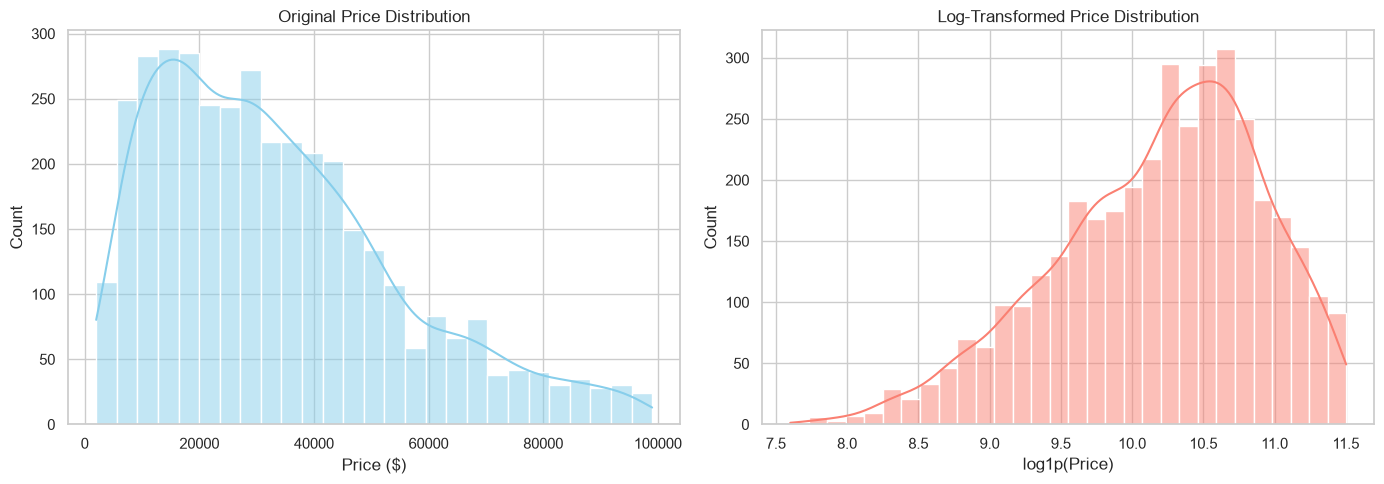

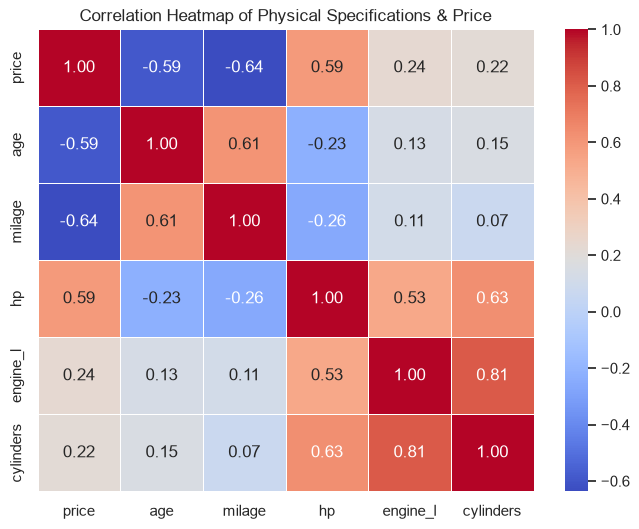

In [5]:
# Price distribution before and after log transform
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df["price"], kde=True, ax=axes[0], color="skyblue")
axes[0].set_title("Original Price Distribution")
axes[0].set_xlabel("Price ($)")

sns.histplot(df["log_price"], kde=True, ax=axes[1], color="salmon")
axes[1].set_title("Log-Transformed Price Distribution")
axes[1].set_xlabel("log1p(Price)")
plt.tight_layout()
plt.show()

# Correlation Heatmap of Numeric Features
plt.figure(figsize=(8, 6))
numeric_cols = ["price", "age", "milage", "hp", "engine_l", "cylinders"]
sns.heatmap(
    df[numeric_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5
)
plt.title("Correlation Heatmap of Physical Specifications & Price")
plt.show()

In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Define features and target
X = df[[
    "age",
    "milage",
    "hp",
    "engine_l",
    "cylinders",
    "fuel_type",
    "transmission",
    "brand_tier",
    "accident",
]]
y = df["log_price"]

# 80/20 Train-Test Split (BEFORE fitting any transformer)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

numeric_features = ["age", "milage", "hp", "engine_l", "cylinders"]
categorical_features = ["fuel_type", "transmission", "brand_tier", "accident"]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            categorical_features,
        ),
    ]
)

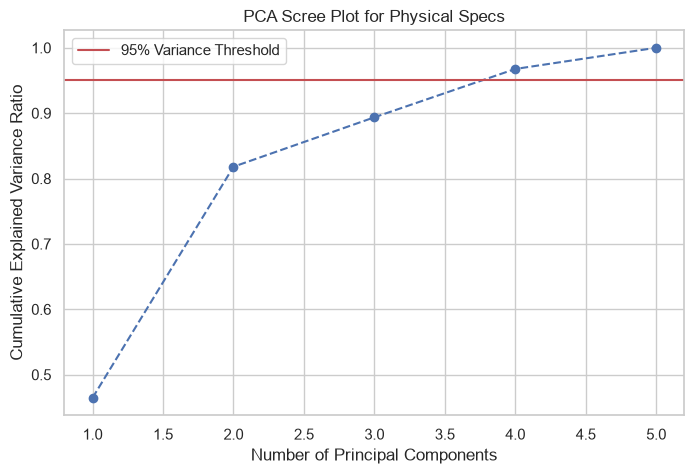

Components needed for 95% variance: 4


In [7]:
from sklearn.decomposition import PCA

# Fit PCA on scaled physical numeric specs to check explained variance
scaler_temp = StandardScaler()
X_train_num_scaled = scaler_temp.fit_transform(X_train[numeric_features])

pca_full = PCA().fit(X_train_num_scaled)
explained_var_ratio = np.cumsum(pca_full.explained_variance_ratio_)

# Scree Plot
plt.figure(figsize=(8, 5))
plt.plot(
    range(1, len(explained_var_ratio) + 1),
    explained_var_ratio,
    marker="o",
    linestyle="--",
)
plt.axhline(y=0.95, color="r", linestyle="-", label="95% Variance Threshold")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance Ratio")
plt.title("PCA Scree Plot for Physical Specs")
plt.legend()
plt.show()

# Let's define a PCA transformer keeping 95% variance
n_components_95 = np.argmax(explained_var_ratio >= 0.95) + 1
print(f"Components needed for 95% variance: {n_components_95}")

In [8]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

# 1. Baseline: Linear Regression
lr_pipeline = Pipeline(
    steps=[("preprocessor", preprocessor), ("regressor", LinearRegression())]
)
lr_pipeline.fit(X_train, y_train)

# 2. Ridge & Lasso with GridSearchCV
alphas = np.logspace(-3, 3, 20)

ridge_grid = GridSearchCV(
    Pipeline(
        steps=[("preprocessor", preprocessor), ("regressor", Ridge())]
    ),
    {"regressor__alpha": alphas},
    cv=5,
    scoring="r2",
)
ridge_grid.fit(X_train, y_train)

lasso_grid = GridSearchCV(
    Pipeline(
        steps=[("preprocessor", preprocessor), ("regressor", Lasso())]
    ),
    {"regressor__alpha": alphas},
    cv=5,
    scoring="r2",
)
lasso_grid.fit(X_train, y_train)

# 3. Gradient Boosting Regressor
gb_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "regressor",
            GradientBoostingRegressor(
                n_estimators=100, learning_rate=0.1, max_depth=4, random_state=42
            ),
        ),
    ]
)
gb_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['age','milage','hp',...,'transmission','brand_tier','accident']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis co


--- Model Evaluation Summary ---


,Model,Test R2,Test RMSE ($),Test MAE ($)
0,Linear Regression,0.691211,11633.888541,7553.558074
1,Ridge (Tuned),0.691251,11633.151953,7552.795271
2,Lasso (Tuned),0.688900,11677.351212,7552.373278
3,Gradient Boosting,0.822499,8820.524552,5994.244098


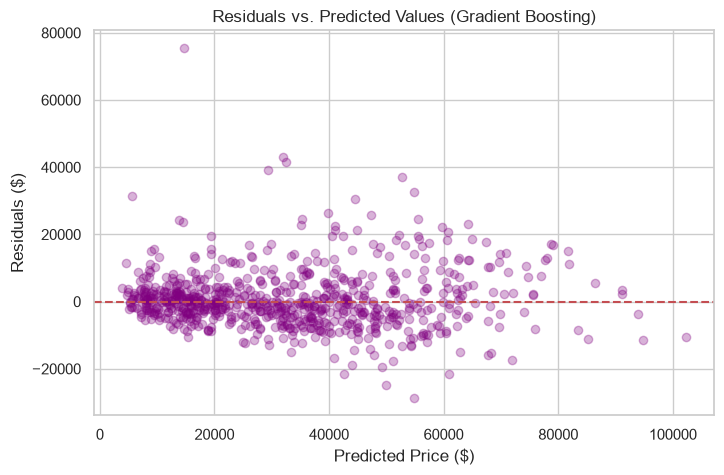

In [9]:
models = {
    "Linear Regression": lr_pipeline,
    "Ridge (Tuned)": ridge_grid.best_estimator_,
    "Lasso (Tuned)": lasso_grid.best_estimator_,
    "Gradient Boosting": gb_pipeline,
}

evaluation_results = []

for name, model in models.items():
  # Predict on train and test (log scale)
  y_pred_train_log = model.predict(X_train)
  y_pred_test_log = model.predict(X_test)

  # Convert back using expm1 for real-dollar evaluations
  y_train_exp = np.expm1(y_train)
  y_test_exp = np.expm1(y_test)
  y_pred_train_exp = np.expm1(y_pred_train_log)
  y_pred_test_exp = np.expm1(y_pred_test_log)

  # Metrics
  r2_test = r2_score(y_test_exp, y_pred_test_exp)
  rmse_test = np.sqrt(mean_squared_error(y_test_exp, y_pred_test_exp))
  mae_test = mean_absolute_error(y_test_exp, y_pred_test_exp)

  evaluation_results.append({
      "Model": name,
      "Test R2": r2_test,
      "Test RMSE ($)": rmse_test,
      "Test MAE ($)": mae_test,
  })

results_df = pd.DataFrame(evaluation_results)
print("\n--- Model Evaluation Summary ---")
display(results_df)

# Residual Analysis for Best Model (Gradient Boosting)
best_model = gb_pipeline
y_pred_test_log = best_model.predict(X_test)
residuals = np.expm1(y_test) - np.expm1(y_pred_test_log)

plt.figure(figsize=(8, 5))
plt.scatter(np.expm1(y_pred_test_log), residuals, alpha=0.3, color="purple")
plt.axhline(y=0, color="r", linestyle="--")
plt.xlabel("Predicted Price ($)")
plt.ylabel("Residuals ($)")
plt.title("Residuals vs. Predicted Values (Gradient Boosting)")
plt.show()

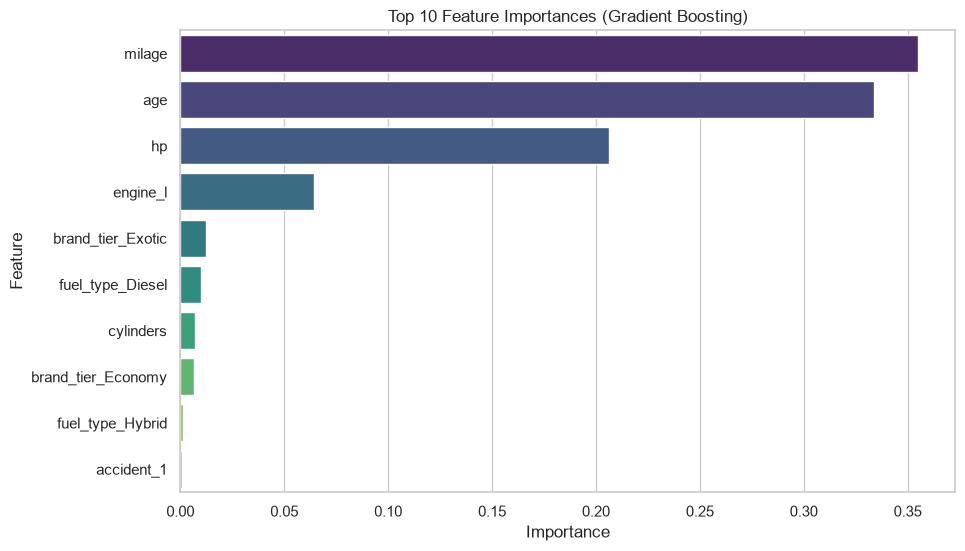

In [10]:
# Feature Importance from Gradient Boosting
gb_regressor = gb_pipeline.named_steps["regressor"]
cat_encoder = (
    gb_pipeline.named_steps["preprocessor"]
    .named_transformers_["cat"]
    .get_feature_names_out(categorical_features)
)
all_features = numeric_features + list(cat_encoder)

importances = gb_regressor.feature_importances_
feat_imp_df = pd.DataFrame(
    {"Feature": all_features, "Importance": importances}
).sort_values(by="Importance", ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(
    x="Importance",
    y="Feature",
    data=feat_imp_df.head(10),
    palette="viridis",
)
plt.title("Top 10 Feature Importances (Gradient Boosting)")
plt.show()

In [11]:
import joblib
joblib.dump(gb_pipeline, "model.joblib")

# quick check: reload it and predict
m = joblib.load("model.joblib")
print(np.expm1(m.predict(X_test.head())))

[19676.87112637 14443.95894577 42636.24234205 52763.96840265
 52161.24271573]
